In [58]:
#imports
from tldhamburg.backend import DataFetcher
import matplotlib.pyplot as plt
import json
import pandas as pd
import numpy as np

In [59]:
#import latency data

with open("latency_analysis.json","r") as file:
    data = json.load(file)

In [60]:
#process data into percentiles
data_copy = data.copy()

sorted_data = {key : sorted(value) for key,value in data_copy.items()}

fifty_percentile = list()
seventyfive_percentile = list()
ninetyfive_percentile = list()

for key,value in sorted_data.items():
    fifty_percentile.append(value[49])
    seventyfive_percentile.append(value[74])
    ninetyfive_percentile.append(value[94])

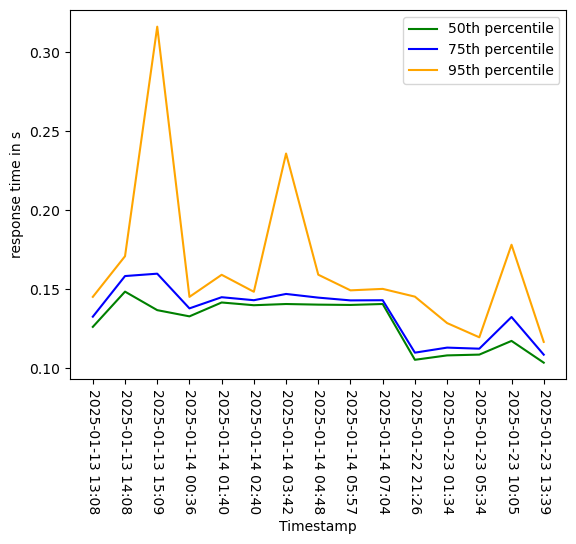

In [61]:
#create plots

timestamps = list(data.keys())

#truncate date stamps
timestamps_pd = pd.to_datetime(timestamps)
truncated_timestamps = timestamps_pd.strftime('%Y-%m-%d %H:%M')

plt.plot(truncated_timestamps,fifty_percentile,color="green", label="50th percentile")
plt.plot(truncated_timestamps,seventyfive_percentile,color="blue", label="75th percentile")
plt.plot(truncated_timestamps,ninetyfive_percentile,color="orange", label="95th percentile")

plt.xlabel("Timestamp")
plt.ylabel("response time in s")

plt.xticks(rotation=270)

plt.legend()

plt.show()

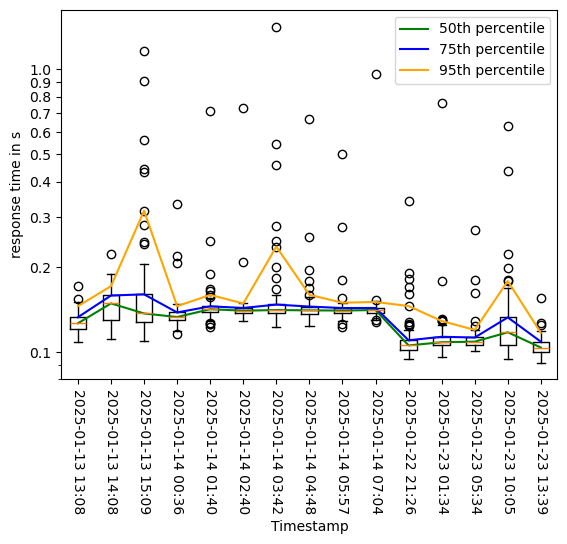

In [64]:
whole_data = list()
for key,value in sorted_data.items():
    whole_data.append(value)

plt.yscale('log')
plt.boxplot(whole_data)

plt.plot(range(1,len(truncated_timestamps)+1),fifty_percentile,color="green", label="50th percentile")
plt.plot(range(1,len(truncated_timestamps)+1),seventyfive_percentile,color="blue", label="75th percentile")
plt.plot(range(1,len(truncated_timestamps)+1),ninetyfive_percentile,color="orange", label="95th percentile")

plt.xlabel("Timestamp")
plt.ylabel("response time in s")

plt.xticks(ticks=range(1,len(truncated_timestamps)+1),labels=truncated_timestamps,rotation=270)
plt.yticks(np.linspace(0.1,1,10),labels=["{:.1f}".format(tick) for tick in np.linspace(0.1,1,10)])

plt.legend()
plt.show()